<img width="200" style="float:left" 
     src="https://upload.wikimedia.org/wikipedia/commons/f/f3/Apache_Spark_logo.svg" />

# Lab 16.1 — Apache Spark DataFrames API, Transport for London Bike Point Analysis
This notebook is organized in the following sections:
* [Description](#0)
* [Notebook environment setup](#1)
* [Step 1 - Ingest Bike point data into MinIO](#2)
  * [NiFi and MinIO start up](#2.1)
  * [NiFi flow import](#2.2)
* [Step 2 - Create a DataFrame containing all the Bike Point info](#3)
  * [DataFrame creation](#3.1)
  * [Shaping the DataFrame to answer business questions](#3.2)
  * [Getting the bikes in use from the additionalProperties column](#3.3)
* [Step 3 - Answering the business question](#4)
* [Environment shutdown](#5)

<a id='0'></a>
## Description
This lab has several objectives:

* Build a DataFrame from multiple JSON files
* Handle slightly more complex data structures, such as arrays of JSON documents
* Run some simple calculations on the data

We will work again with our Transport for London dataset, specifically the Bike Points data we explored before. The question we want to answer is:
***“What are the minimum, maximum, and average numbers of bikes used this month?”***

<a id='1'></a>
## Notebook environment setup
Create a folder named `/mda1/tfl_bikepoint_analysis` in your Jupyter Notebook environment and place all the files used throughout this exercise inside it. Keeping everything organized in a single location will make it easier to follow the examples and better understand each step of the process:

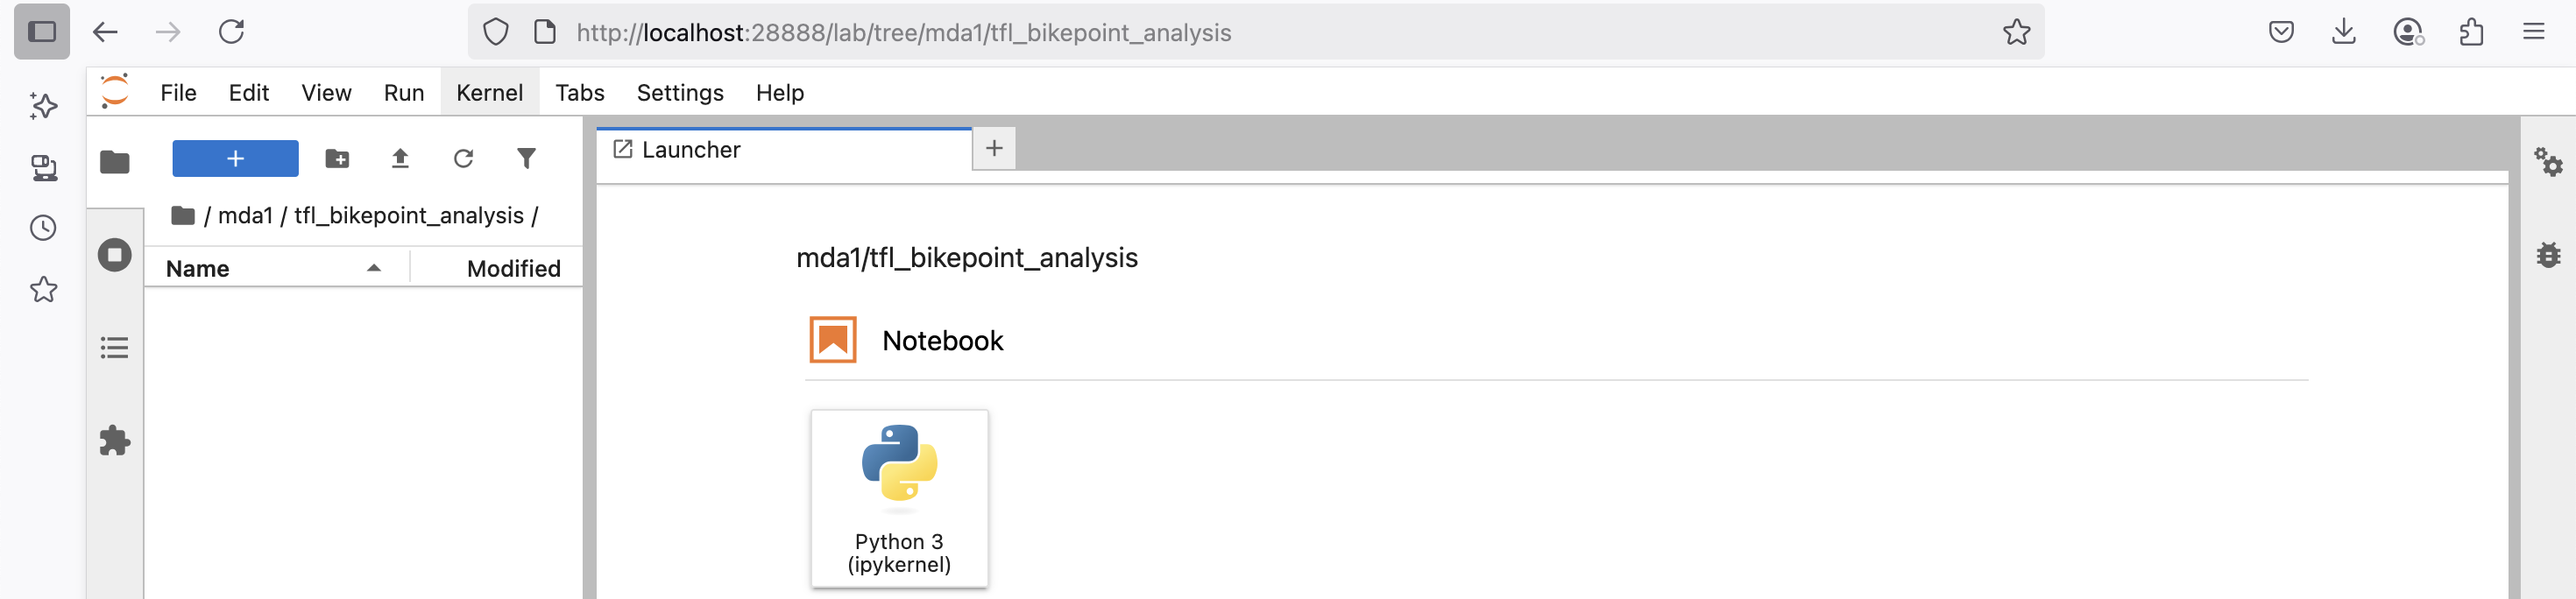

We will use **Pandas** to **display the results in a more readable format**, so let's configure it first:

In [ ]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

Now it's **time to create the [Spark Session](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.html)** before we can do anything else. Remember, the Spark Session *is the entry point for working with Spark through the DataFrame API (the high-level API)*.

In [ ]:
from pyspark.sql.session import SparkSession

spark_session = \
  SparkSession.builder\
              .appName("Transport for London, Bike point analysis")\
              .getOrCreate()

print(f"This cluster relies on Spark '{spark_session.version}'")

<a id='2'></a>
## Step 1 - Ingest Bike point data into MinIO
We are going to import a preconfigured NiFi flow to collect Bike Points data from Transport for London every 5 minutes. The flow will ingest the data into **the raw-data bucket in MinIO**, where it will be ready for Spark to analyze later. The data will be stored in **[JSON Lines](https://jsonlines.org/)** format, which Spark can process easily.

<a id='2.1'></a>
### NiFi and MinIO start up

Let’s **start NiFi and MinIO and make them available** by turning them on from the [OSBDET's Web UI](http://localhost:2026):

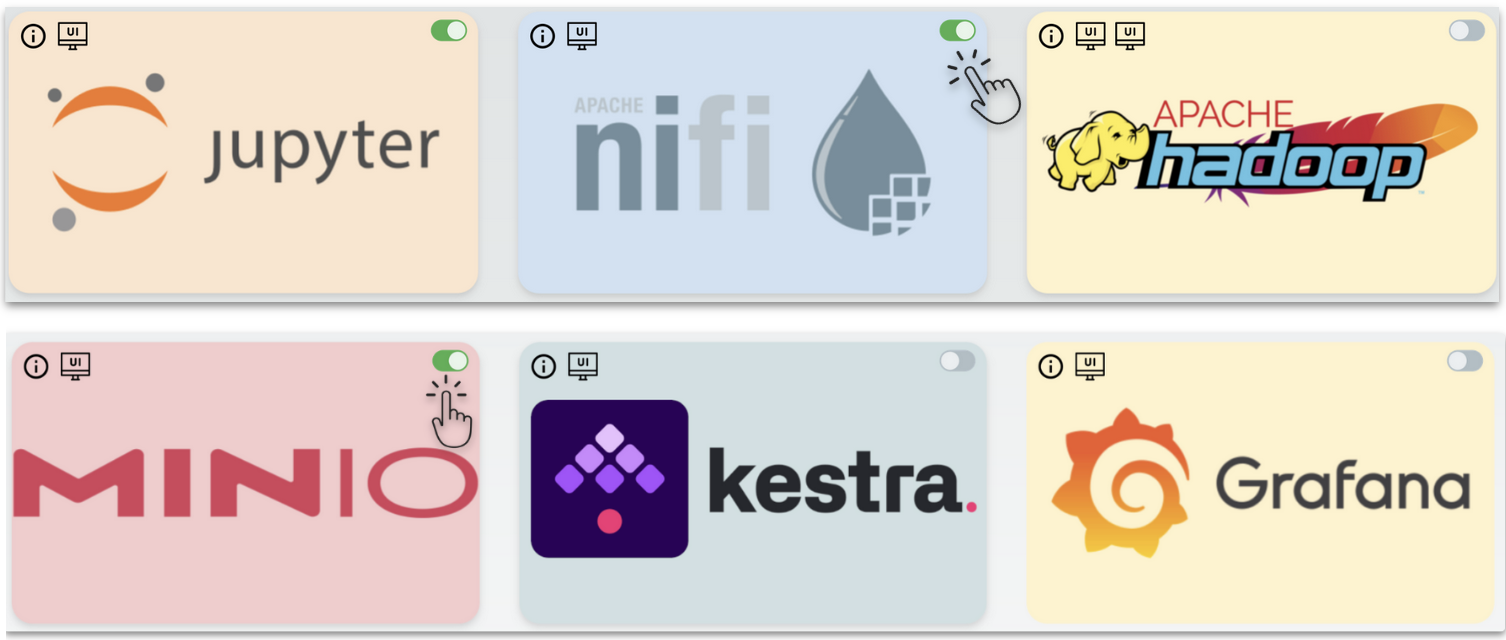

<a id='2.2'></a>
### NiFi flow import

1. **Download** the `TfL_Bike_Points_info_to_MinIO_(S3).json` file from Blackboard.
2. **Access** the [Apache NiFi UI](http://localhost:29090/nifi/).
3. **Create a new Process Group** from the JSON file containing the NiFi flow.
4. Name it **`TfL Bike Points info to MinIO (S3)`**.
5. **Confirm the creation**.

**Note:** A warning icon will appear in the created Process Group, which is expected.

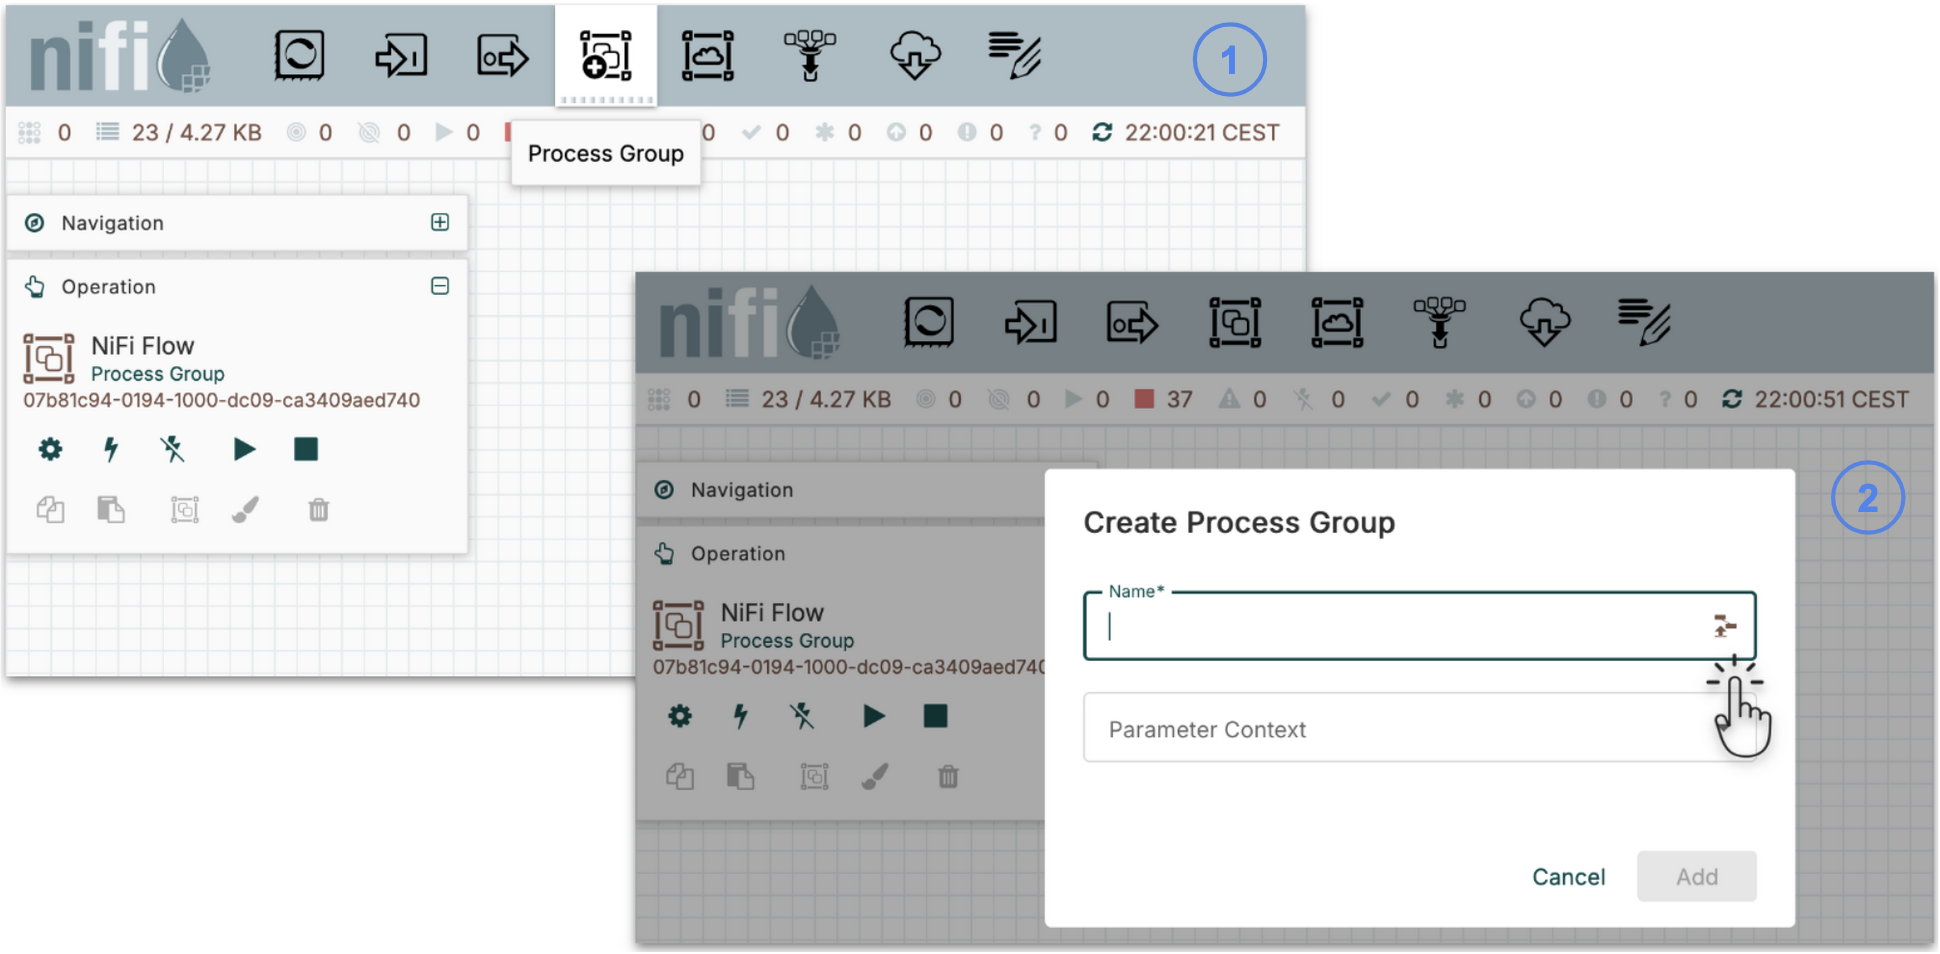

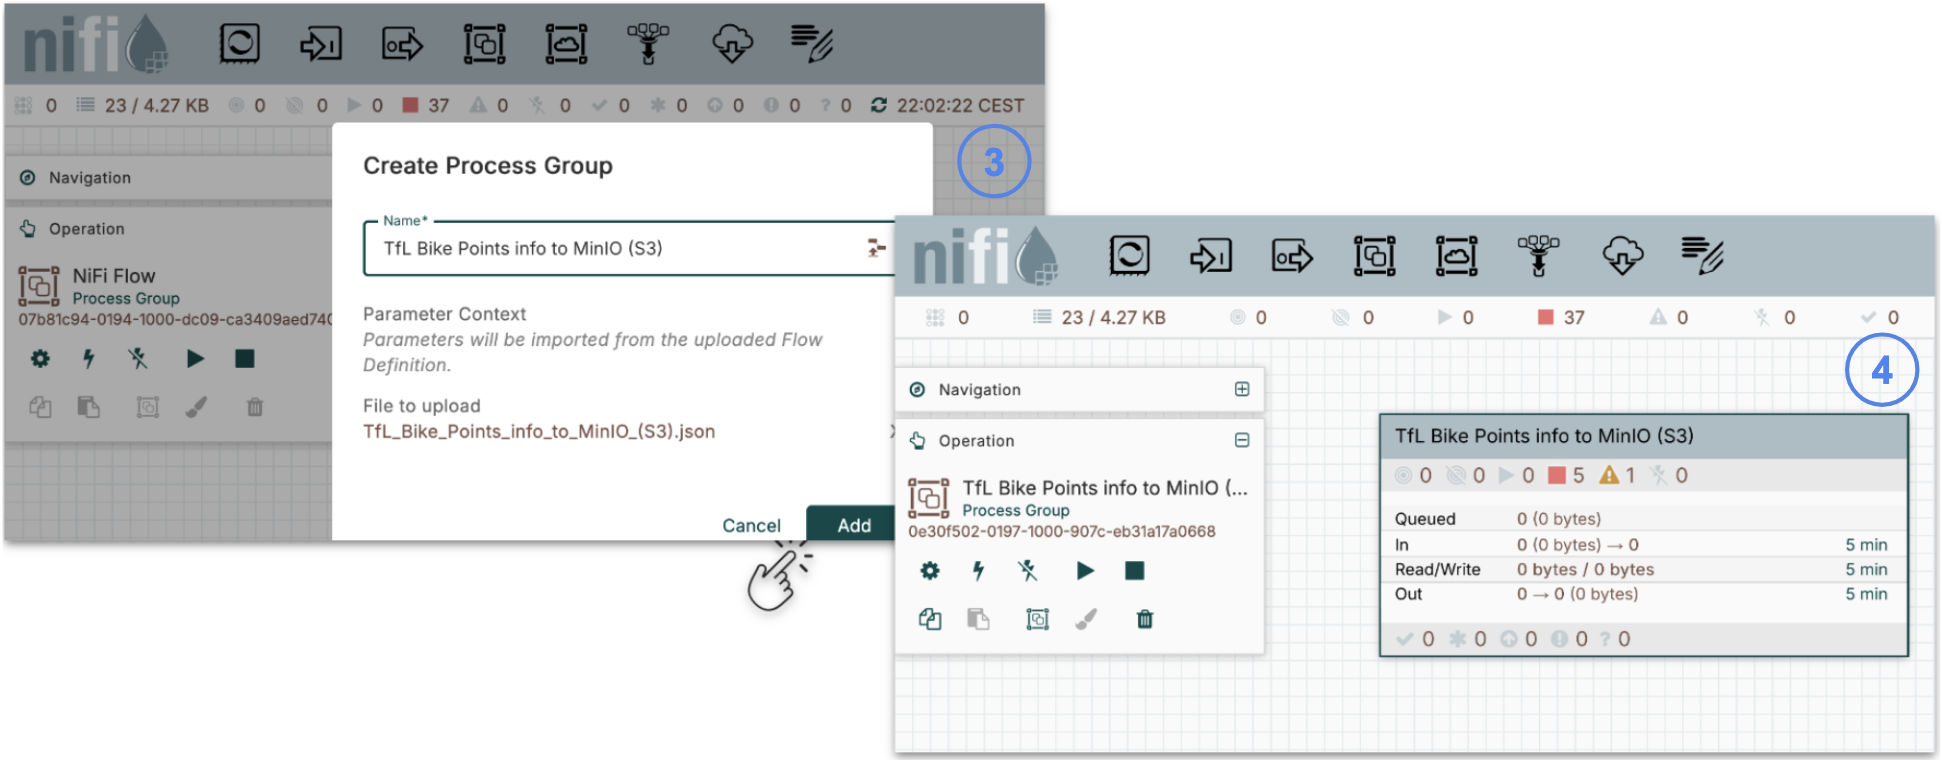

We are almost there! Before continuing with the exercise, we need to remove the warning message. To do that, we must **add the credentials that allow NiFi to access MinIO**, which is something we already configured in previous labs (for example, the NiFi Lab: Batch & Streaming Dual Ingestion Binance).

*Double-click the Process Group to access its contents* and configure the **“Controller Services”** (*right-click on the canvas and then select “Controller Services”*):

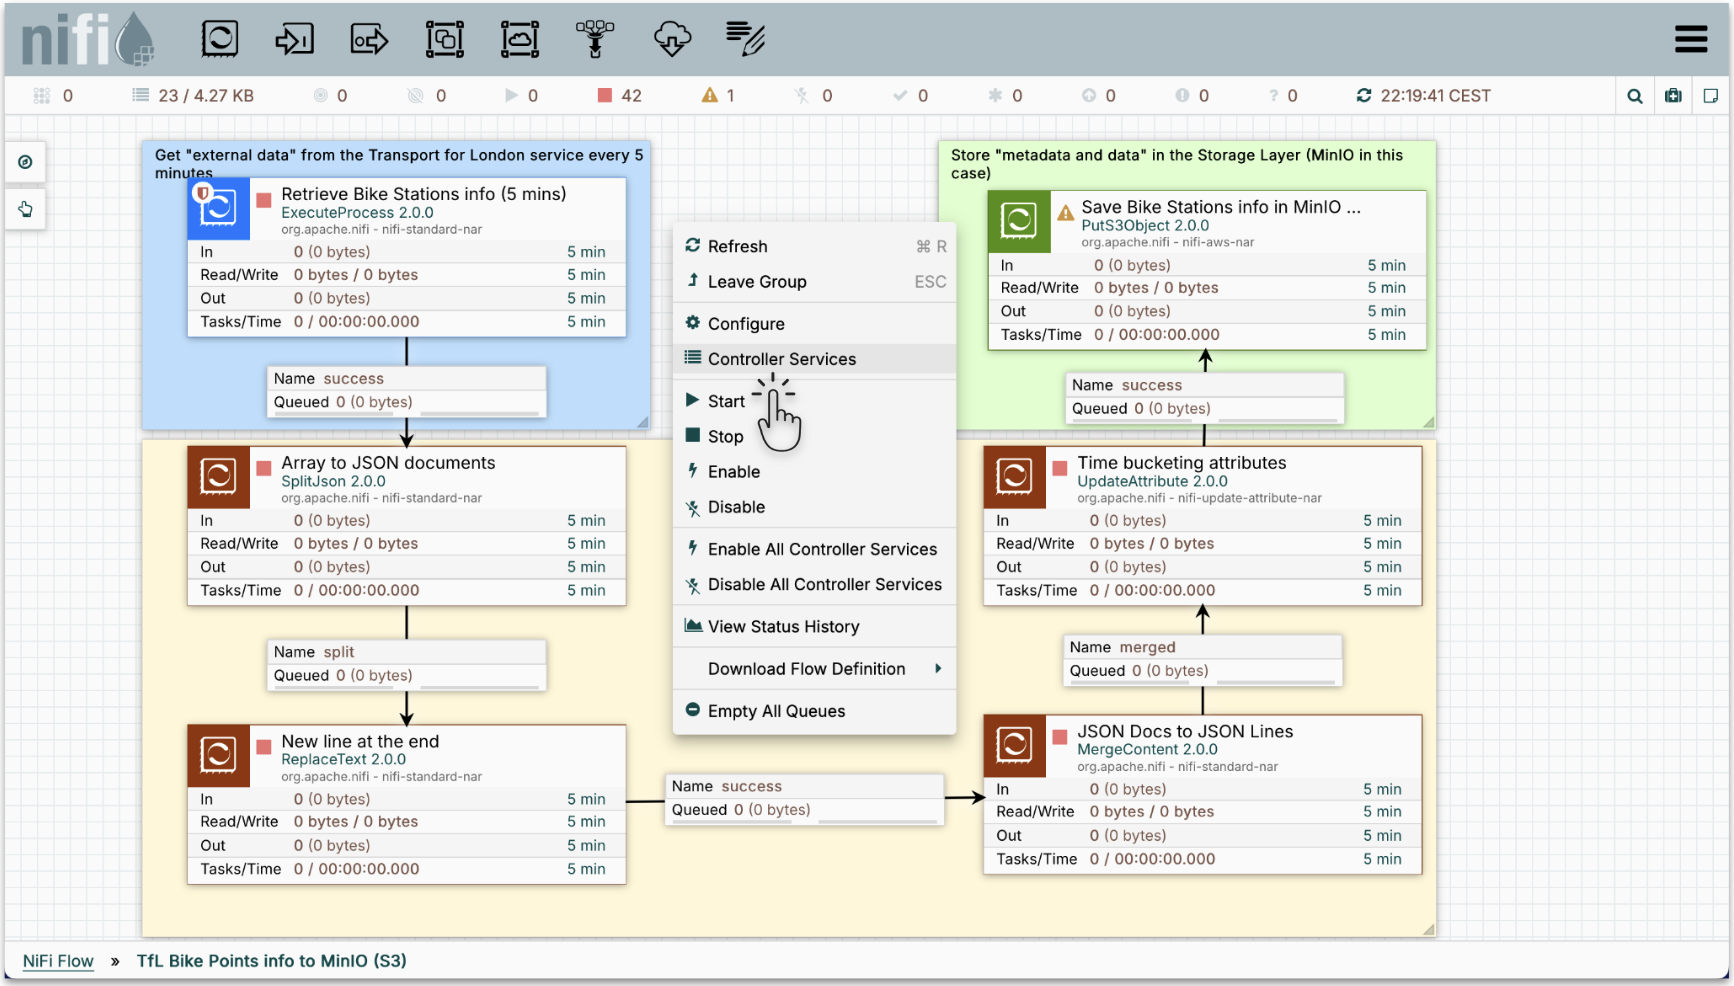

Edit the `AWSCredentialsProviderControllerService` Controller Service and configure the following parameters:

* **Access Key ID:** `s3access`
* **Secret Access Key:** `_s3access123$`

*Sensitive information*, such as usernames and passwords, is not included in exported flows. Therefore, **these values must be added manually after importing the flow**.

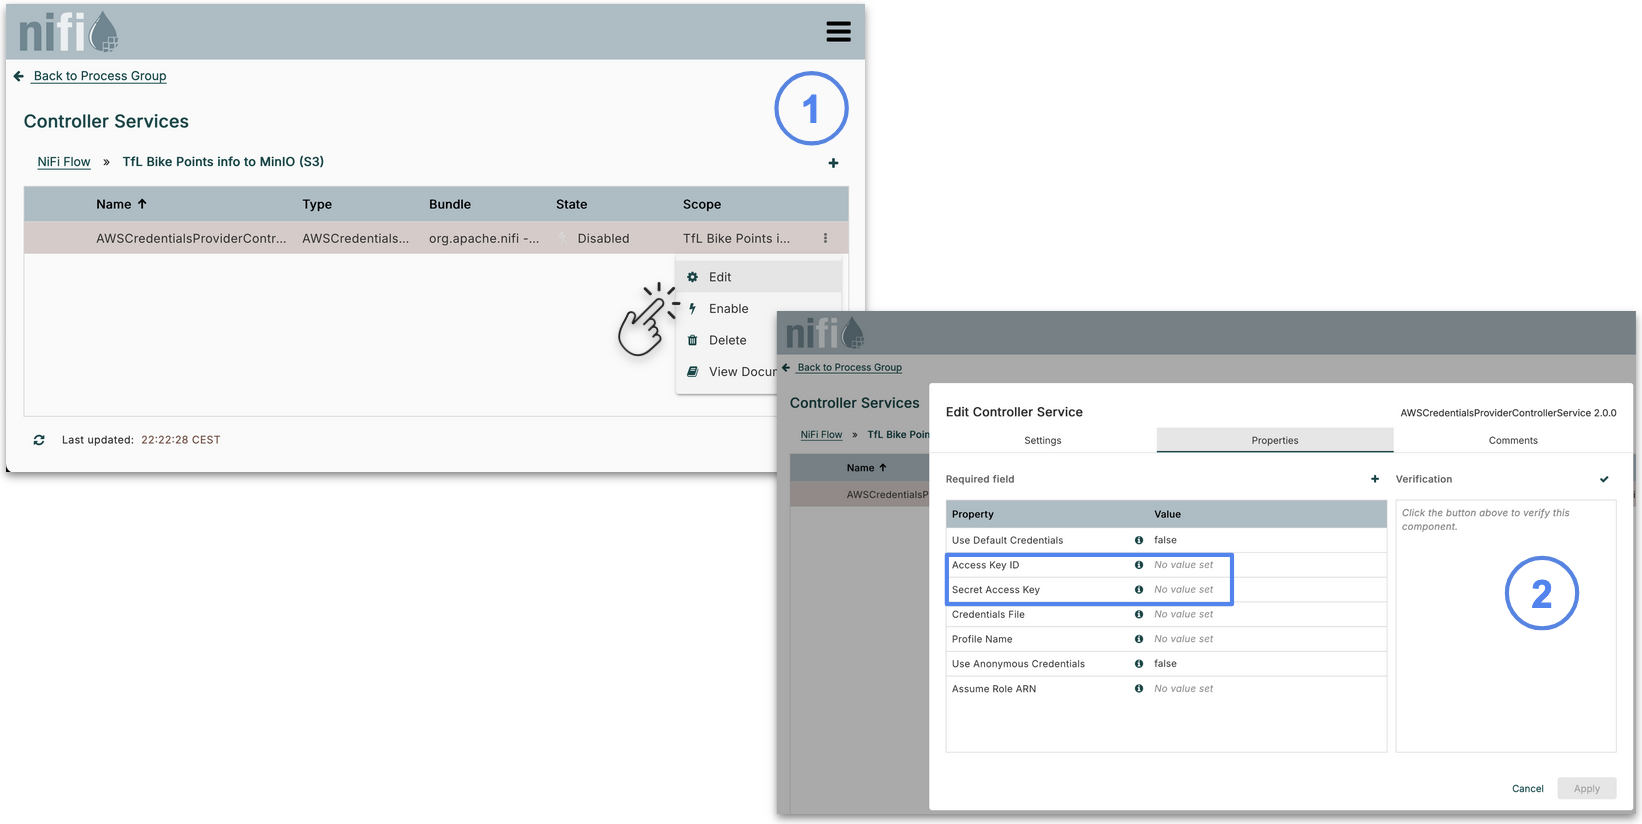

Finalize the configuration by following these steps:

1. Apply the changes.
2. **Enable** the `AWSCredentialsProviderControllerService` Controller Service and close that screen.
3. **Click on the canvas to make sure no processor is selected**.
4. **Press the play button to start the entire Process Group*.

If everything is configured correctly, all processors should start running without any error messages.

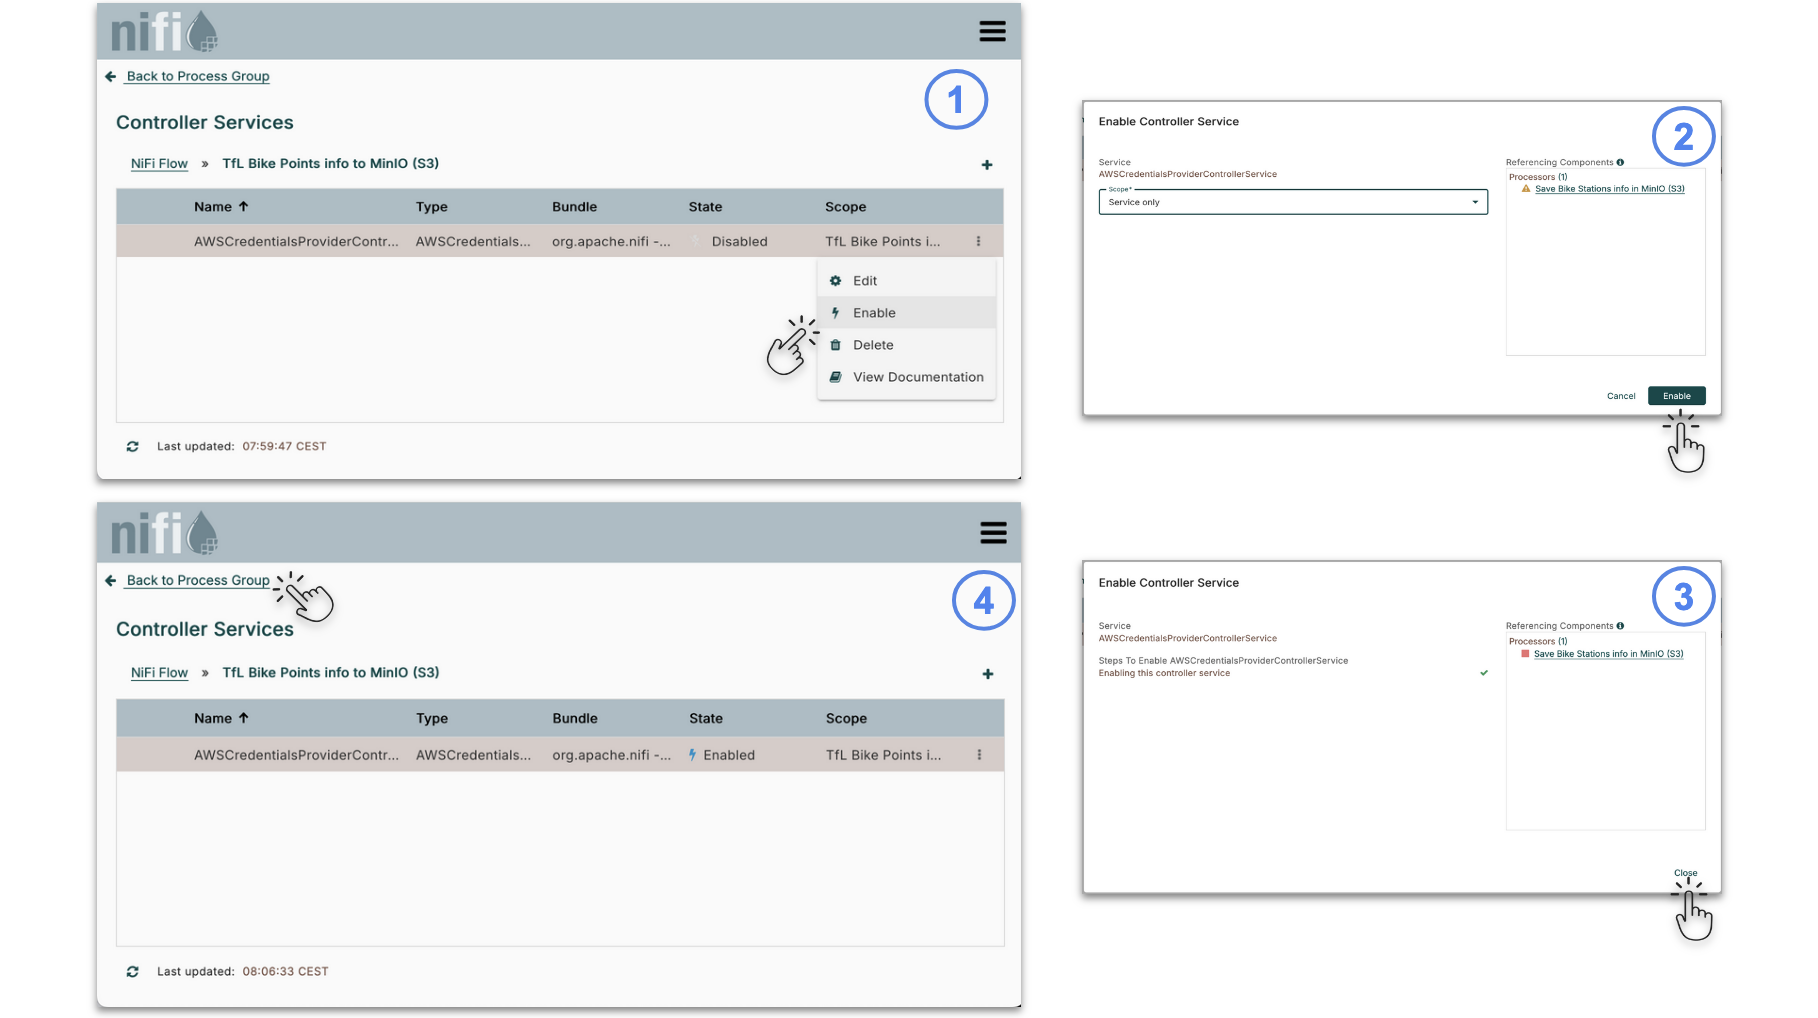

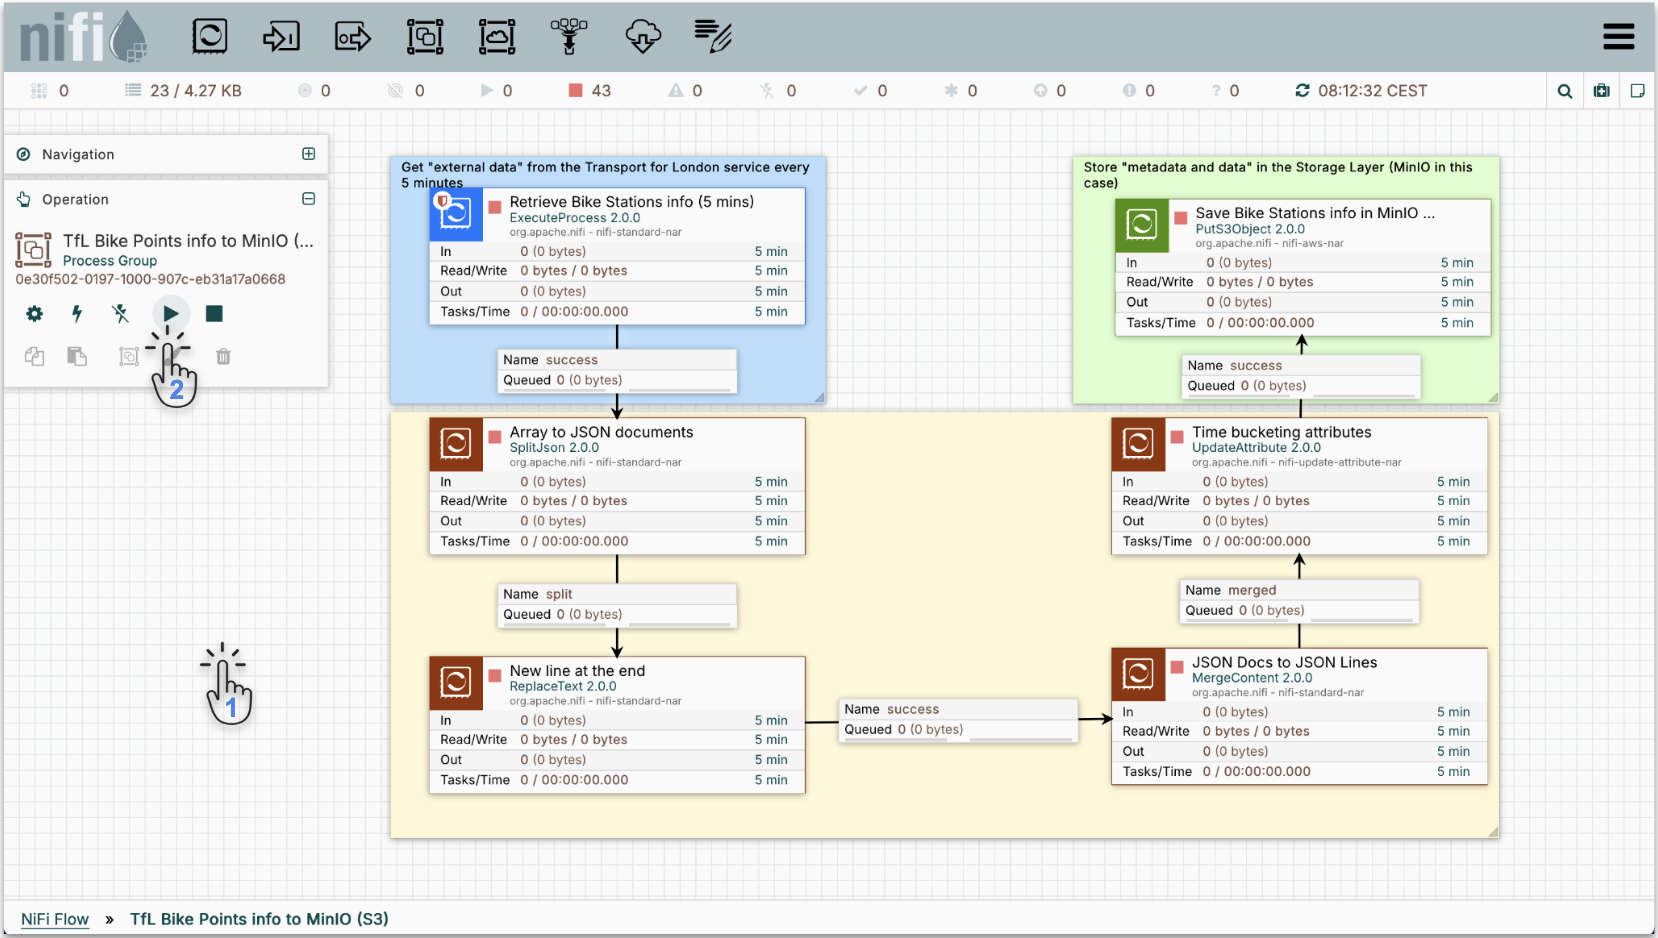

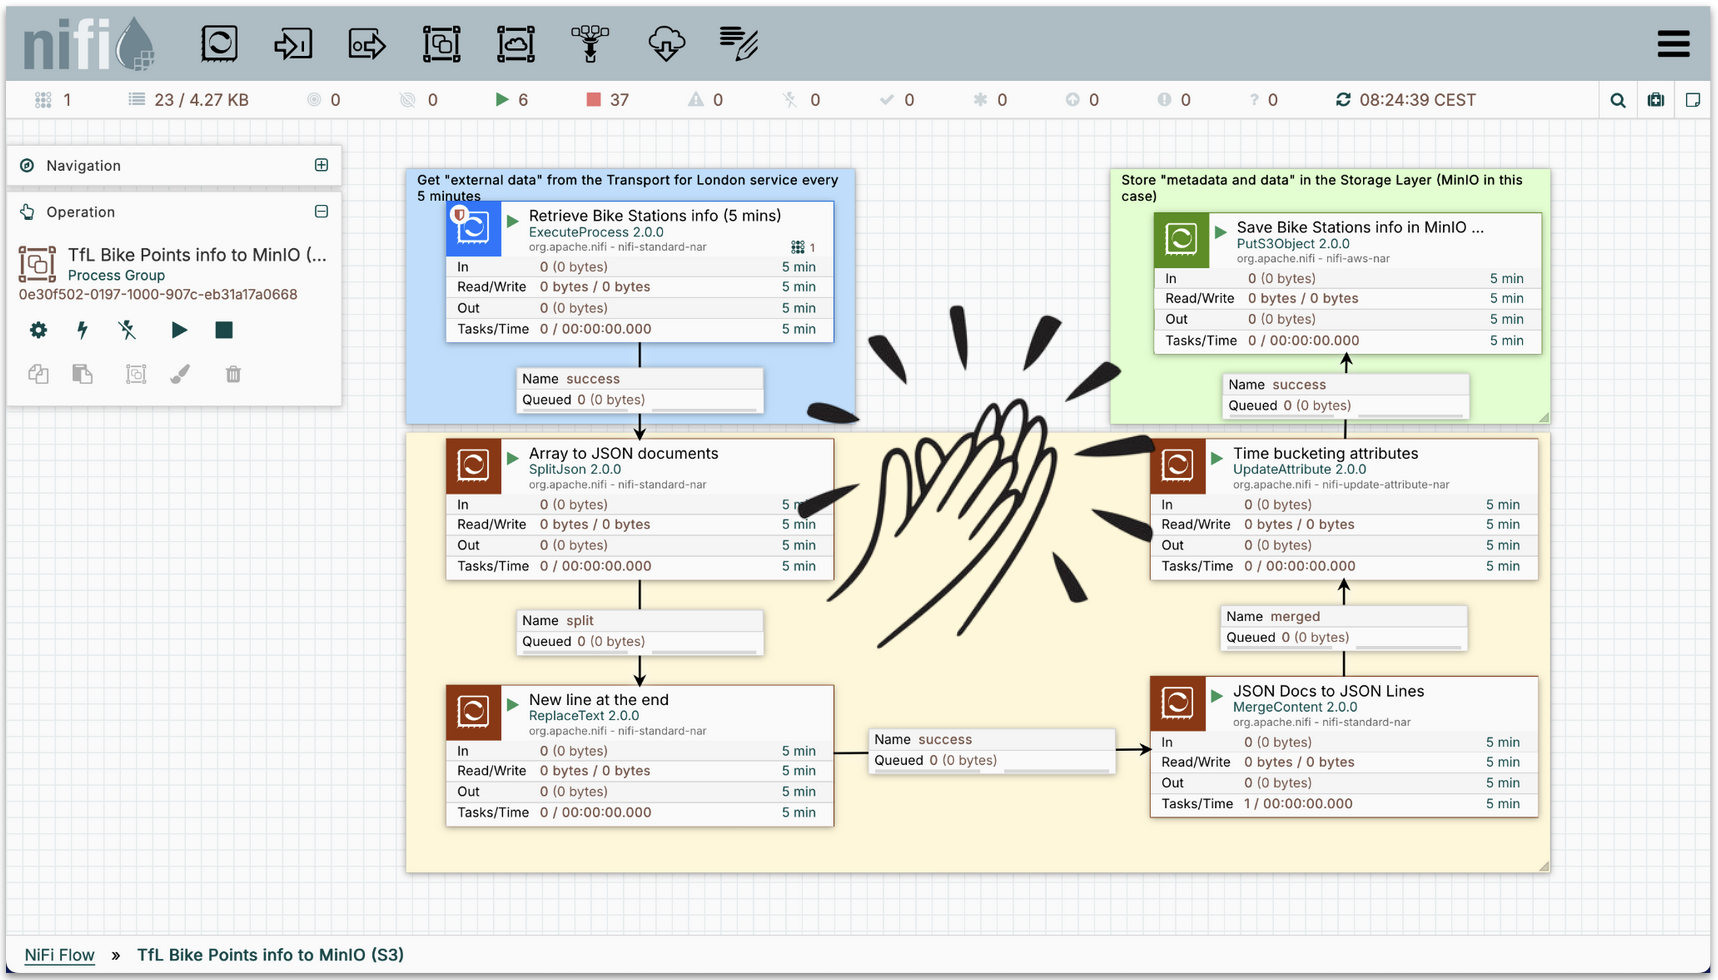

<a id='3'></a>
## Step 2 - Create a DataFrame containing all the Bike Point info

You can easily create a DataFrame from multiple files ***by using wildcards (*) in the filenames stored in MinIO***. Although more advanced regular expressions can be used for more specific filtering, that is outside the scope of this course.

The filename format has been designed as follows: `bikepoints_yyyyMMdd_HHmm.json`, where:

* **`yyyy`** represents the year
* **`MM`** represents the month
* **`dd`** represents the day
* **`HH`** represents the hour (00–23)
* **`mm`** represents the minute

Since the data is **partitioned by year, month, day, and hour**, you can use **wildcards to include multiple files**. For example, to load all files for July 2024 (your dates will differ), you could use the following pattern: `bikepoints_202407*_*.json`.

Additionally, you may want to **include a new column in the DataFrame containing the filename associated with each row**. We will not use it in this lab, but it can be useful in certain scenarios.

<a id='3.1'></a>
### DataFrame creation

We need to tell the Spark Session **how to access MinIO**, our *S3-compatible object store*:

In [ ]:
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.access.key", "s3access")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.secret.key", "_s3access123$")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.path.style.access", "true")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.endpoint", "http://localhost:9000")

We are now ready to **create the DataFrame from the data stored in MinIO**, which will allow us to *begin the Exploratory Data Analysis (EDA)*:

In [ ]:
import pyspark.sql.functions as F

bikepoint_raw_df = spark_session.read\
                                .json("s3a://raw-data/bikepoints_*.json")

# DataFrame updated with an additional column containing the filename contributing to the data in every row.
bikepoint_raw_df = bikepoint_raw_df.withColumn("filename_path", F.input_file_name())

# The inferred schema can be visualized using the printSchema() method - definitely semi-structured data.
bikepoint_raw_df.printSchema()

Let’s display the **last 10 files contributing to the DataFrame** by using some of the transformations we have already studied:

* First, let’s reduce the DataFrame to display only the *filename_path column*. Remember that DataFrames are immutable, so transformations do not modify the original DataFrame:

In [ ]:
bikepoint_raw_df.select("filename_path").printSchema()

In [ ]:
bikepoint_raw_df.printSchema()

* Hopefully, the last two cells helped you better understand what ***“immutability in DataFrames” means***. Now it is time to list the last 10 files contributing to the DataFrame:

In [ ]:
bikepoint_raw_df.select("filename_path")\
                .distinct()\
                .orderBy(F.col("filename_path").desc())\
                .limit(10)\
                .toPandas()

<a id='3.2'></a>
### Shaping the DataFrame to answer business questions

Once your files are available in the batch storage layer, your goals will be:

1. ***Define the logic you need*** to implement in Spark to answer the required business questions.
2. ***Adapt the initial “raw” DataFrame*** to create a structure that simplifies the implementation of that logic. This approach is often called ["Schema on Read"](https://www.geeksforgeeks.org/what-is-schema-on-read-and-schema-on-write-in-hadoop/) and is a very powerful way to make the most of the data stored in your storage layer.
3. ***Translate the logic into Spark code*** that will define your Spark job.

Since the business question we need to answer is ***"What are the minimum, maximum, and average numbers of bikes used during the current month?"***, we need to create a DataFrame containing the following elements:

1. ***The identifier of each Bike Point*** and its name
2. ***The GPS location of each Bike Point***, in case we want to plot the results on a map later
3. ***The number of bikes in use*** per Bike Point over time

<a id='3.3'></a>
### Getting the bikes in use from the additionalProperties column
The number of bikes currently in use (along with other information) is stored in **the array of JSON documents contained in the additionalProperties column***. The information we need is specifically found in the ***key*** and ***value*** fields:

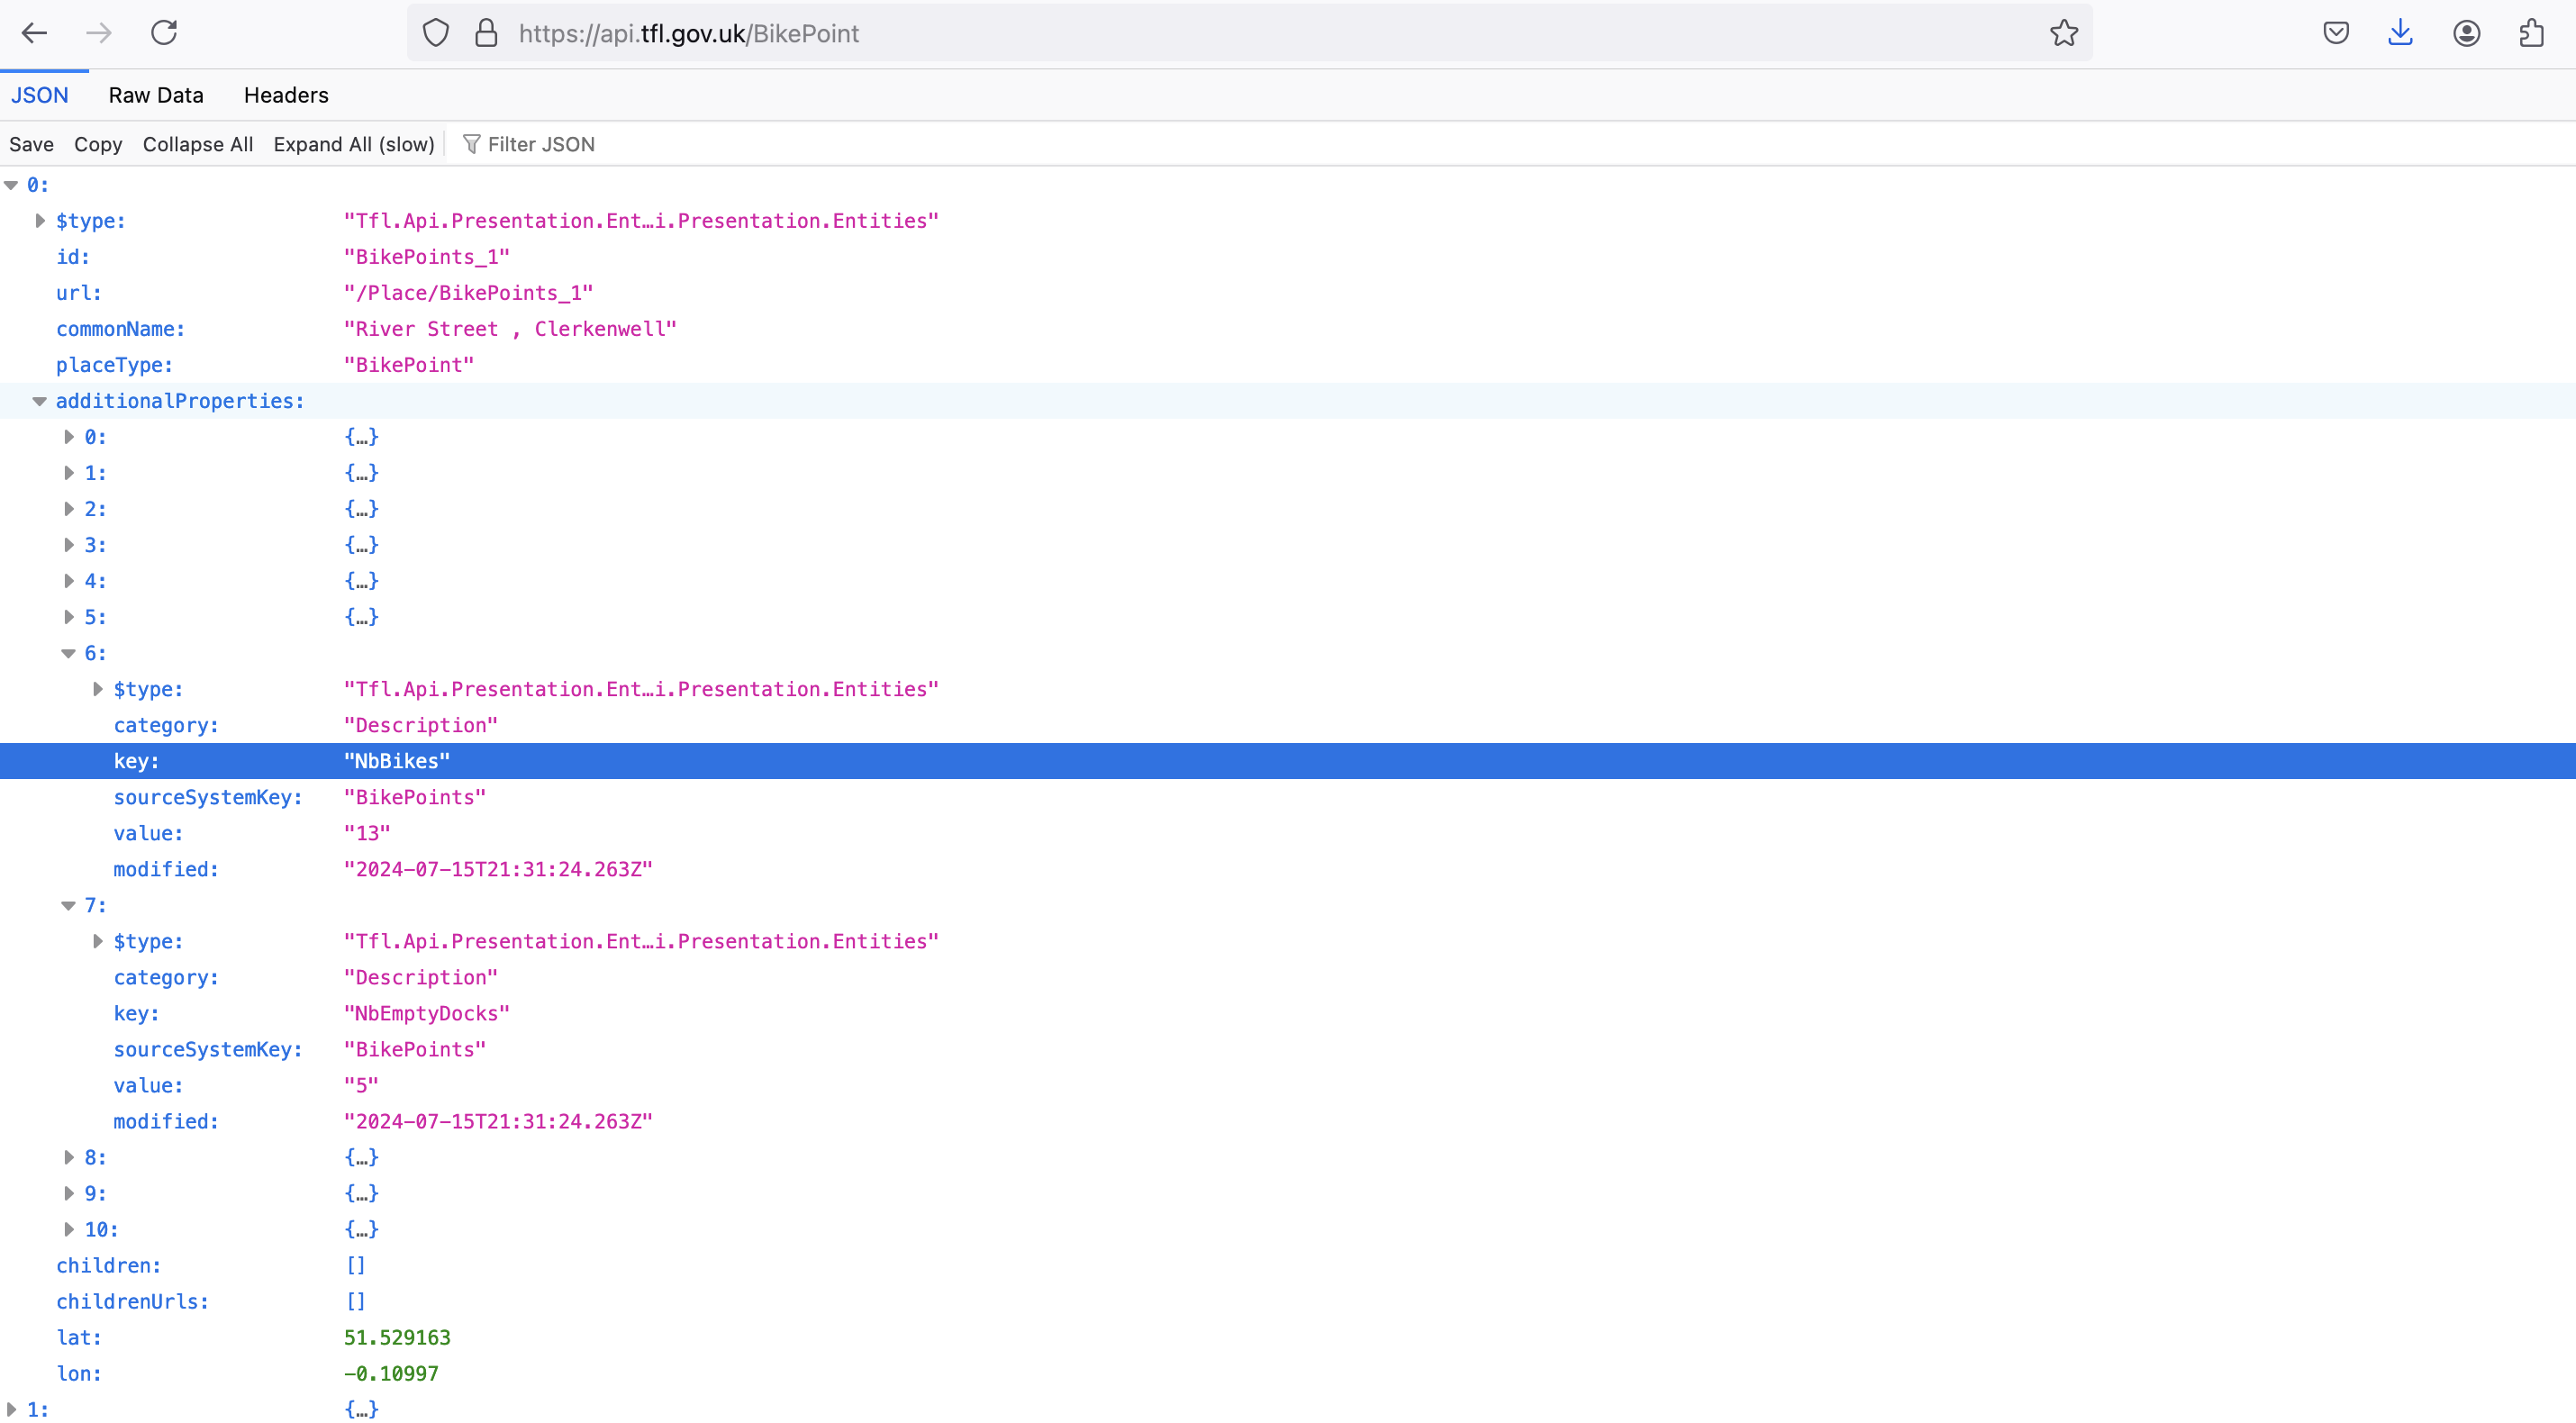

Additionally, we will keep the ***modified*** key, as it may be useful in the future (although it will not be needed in this lab).

In [ ]:
bikepoint_raw_df.limit(1).select("additionalProperties")\
                         .toPandas()

To *flatten* an array column, you need to use the [PySpark explode function](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.explode.html). The combination of `explode` and `withColumn` will:

* Take each element from the array (each JSON document in our case)
* Create a new row for every element while keeping the original values of the other columns
* Add a new column containing the corresponding element (the JSON document) extracted from the array

As you can see, **the number of rows in the DataFrame has increased significantly because each element in the array now generates a separate row**. This is one of the reasons why Spark is especially useful for processing and transforming large datasets efficiently.

In [ ]:
bikepoint_raw_df.withColumn("additional", F.explode("additionalProperties"))\
                .printSchema()

In [ ]:
number_of_elements = bikepoint_raw_df.limit(1)\
                                     .withColumn("additional", F.explode("additionalProperties"))\
                                     .count()
print(f"Starting with 1 row and ending up with {number_of_elements} rows.")

We now have a better understanding of the structure of the raw DataFrame, and we are ready to create a new DataFrame containing the information we need: ***Bike Point identifier, name, location, and number of bikes in use***.

In [ ]:
bikepoint_df = bikepoint_raw_df.withColumn("additional", F.explode("additionalProperties"))\
                               .select("id", "commonName", "lat", "lon",
                                       "additional.key","additional.value","additional.modified")
bikepoint_df.printSchema()

In [ ]:
bikepoint_df.limit(10)\
            .toPandas()

In [ ]:
bikepoint_in_use_df = bikepoint_df.where("key='NbBikes'")
bikepoint_in_use_df.limit(10)\
                   .toPandas()

<a id='4'></a>
## Step 3 - Answering the business question
We are now ready to answer the business question we have been asked: ***"What are the minimum, maximum, and average numbers of bikes used during the current month?"***

In [ ]:
bikepoint_in_use_stats_df = bikepoint_in_use_df.groupBy("id","key")\
                                               .agg(F.min("value"), F.max("value"), F.avg("value"))
bikepoint_in_use_stats_df.printSchema()

In [ ]:
bikepoint_in_use_stats_df.limit(10).toPandas()

***The `bikepoint_in_use_stats_df` DataFrame contains the answer to our business question***. As a next step, you can visualize this data using any visualization framework (such as Matplotlib or Seaborn) or any BI tool of your choice (such as Superset or Tableau).

<a id='5'></a>
## Environment shutdown

Now that we are done working with the dataset, **let’s stop MinIO and NiFi to release resources** by switching them off:

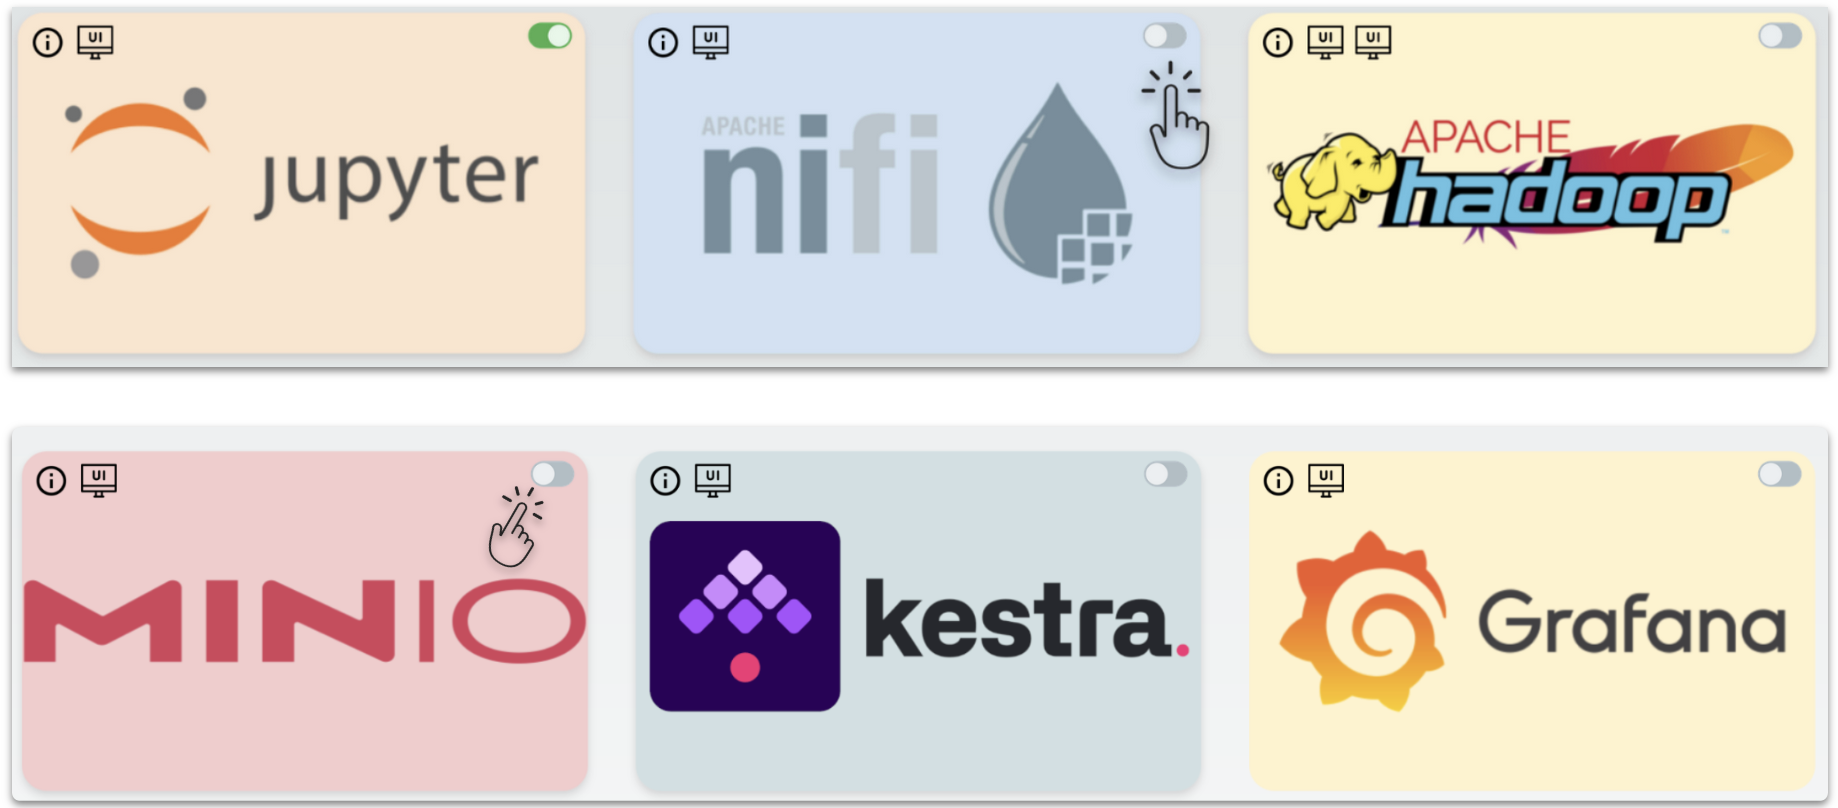

Last but not least, **do not forget to stop your course environment** to release resources and *prevent other applications from being affected or becoming slow*:

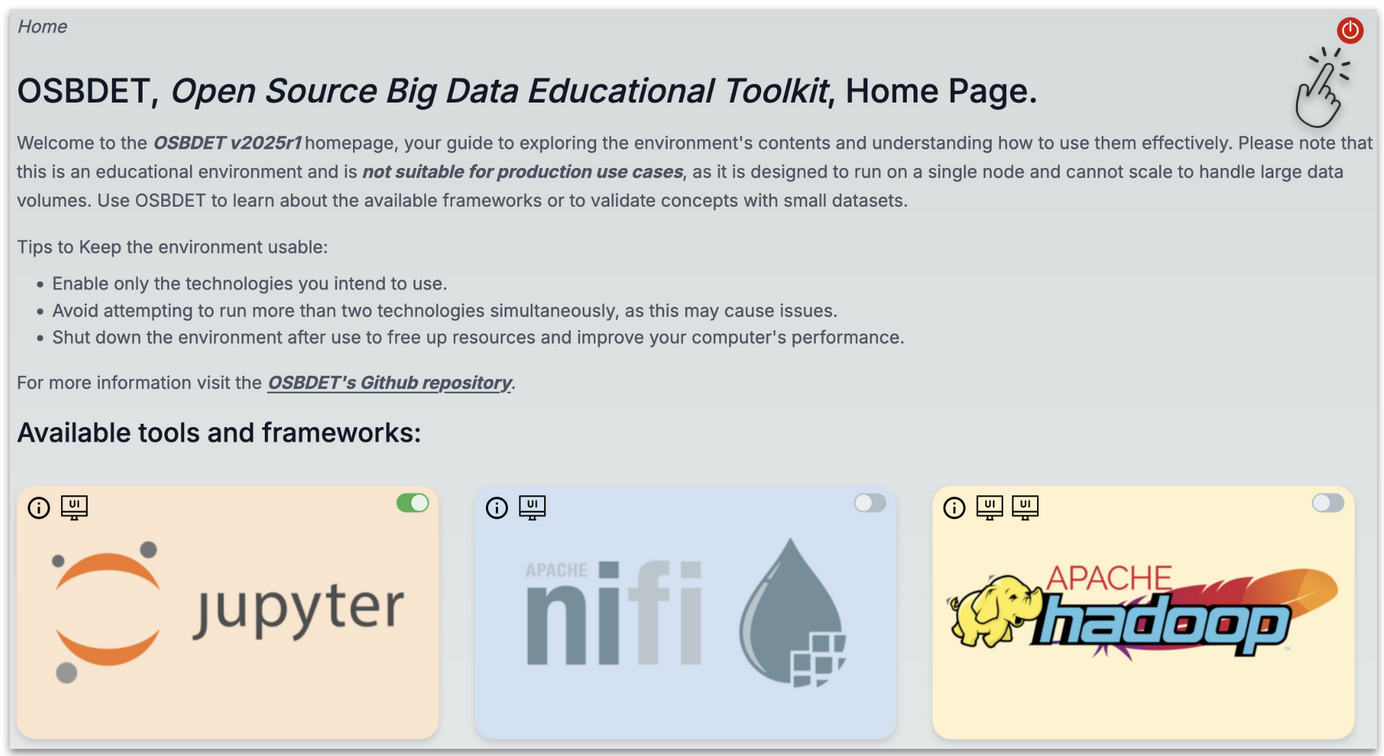